In [1]:
# === Imports ===
import pickle
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
import astropy.units as u  # Physical units
import scipy.optimize as spopt  # Optimization algorithms
import sys

from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
from scipy.stats import binned_statistic, median_abs_deviation
from scipy.interpolate import UnivariateSpline, LSQUnivariateSpline
from scipy.interpolate import interp1d

## Defining Functions

In [2]:
def gmi_diam_zang(color, i, d):
    '''
    Calculate stellar radii from g-i and i, based on Zang 2018
    https://ui.adsabs.harvard.edu/abs/2018PASP..130j4401Z/abstract
    ---
    color : (g-i) color for the stars
    i : i-band magnitude for the stars
    d : distance to the stars in kpc
    '''
    # log_theta = c0 + c1(X-Xp)
    X = color
    log_diam_0 = 0.920 + 0.316*(X-0.576)
    log_diam_g = log_diam_0 - 0.2*i
    stellar_diams = 10**log_diam_g # in mas
    
    # r = diam/2*w
    r_sol = 0.00465 # AU/R_sol
    w = 1/d # parallax, [mas]
    rads = stellar_diams/(2*w) # AU
    rads_sol = rads/r_sol # AU/(AU/R_sol) = AU*R_sol/AU = R_sol
    
    return stellar_diams, rads_sol

In [3]:
# === Isochrone Filter and Radii Calculation Function ===

'''
This function takes the name of your isochrone file and a log(age), filters the isochrone file for the appropriate 
    age, and calculates the stellar radii from the luminosity, temperature, etc.

The age of the bulge is another complicated question, but we've been using 10^10 years as the age. 
    So log(age) should just be 10.
'''
def load_iso(isofile,logages_):
    # these are just column numbers
    cRadius=0
    cMass=3
    cMini=2
    cMI=13
    cMTESS=-2
    cMGaia=-5
    cLum=6
    cTeff=4
    cAge=1
    logages = logages_
    
    # if you want multiple ages, give them as a list and this will keep all of them. Otherwise just give a single one.
    if isinstance(logages_,list):
        logages = np.array(logages_)
    elif not isinstance(logages_,np.ndarray):
        logages = np.array([logages])
    
    # Load isochrone, skipping rows that just have comments
    iso = pd.read_csv(isofile, sep='\\s+', header=None, skiprows=13, engine='python', comment='#')
                                                                                            
    #Replace the idx column with the radii                                                                  
    iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))
            
    # this does the actual filtering for the age(s) you want
    ret = []
    for i, logage in enumerate(logages):
        ret.append(iso[(iso.iloc[:,-1] <= 4.0) & (np.abs(iso.iloc[:,cAge]-logage)<0.001)])
    if len(ret)==1:
        ret = ret[0]
    
    return ret

## Loading in Files and Naming Columns

In [4]:
# === Load in Pickle Files ===
pipedir = '/home/bernthold.17/SURP2025/'
rmz_gmi_spline_file = open(f"{pipedir}/Transforms/psrmz_psgmi_transform.pickle", 'rb')
rmz_imz_spline_file = open(f"{pipedir}/Transforms/psrmz_psimz_transform.pickle", 'rb')

rmz_gmi_spline = pickle.load(rmz_gmi_spline_file)
rmz_imz_spline = pickle.load(rmz_imz_spline_file)

rmz_gmi_spline_file.close()
rmz_imz_spline_file.close()

/tmp/slurmtmp.9109775/ipykernel_2222890/1832519988.py:6: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  rmz_gmi_spline = pickle.load(rmz_gmi_spline_file)
/tmp/slurmtmp.9109775/ipykernel_2222890/1832519988.py:7: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to acce

In [5]:
# === Load in MISHAPS File ===
catalog_path = "/home/bernthold.17/SURP2025/Data_Files/MISHAPS_F1_DITH0_N10.cmd.calibrate_ps"
contents = pd.read_csv(catalog_path, header = None, sep = '\\s+')

# === Apply Column Headers ===
column_labels =['ID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'mis_z', 'mis_z_err', 'Sky_z', 'qflag_z', '?1z', '?2z',
       'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'mis_r', 'mis_r_err', 'Sky_r', 'qflag_r', '?1r', '?2r',
       'RA_u', 'Dec_u', 'ID_u', 'X_u', 'Y_u', 'mis_u', 'mis_u_err', 'Sky_u', 'qflag_u', '?1u', '?2u',
       'RA_g', 'Dec_g', 'ID_g', 'X_g', 'Y_g', 'mis_g', 'mis_g_err', 'Sky_g', 'qflag_g', '?1g', '?2g',
       'RA_i', 'Dec_i', 'ID_i', 'X_i', 'Y_i', 'mis_i', 'mis_i_err', 'Sky_i', 'qflag_i', '?1i', '?2i',
       'RA_Y', 'Dec_Y', 'ID_Y', 'X_Y', 'Y_Y', 'mis_Y', 'mis_Y_err', 'Sky_Y', 'qflag_Y', '?1Y', '?2Y']
              
contents.columns = column_labels

### Filter the Data

In [6]:
# === Apply Quality Filters ===
print(contents.shape)

# mask_flags = (contents['qflag_i'] == 1) & (contents['qflag_g'] == 1) & (contents['qflag_r'] == 1) & (contents['qflag_z'] == 1)
mask_err = (contents['mis_g_err'] < 0.2) & (contents['mis_i_err'] < 0.2) & (contents['mis_r_err'] < 0.2) & (contents['mis_z_err'] < 0.2)
# mask_sky = (contents["Sky_g"] < 25) & (contents["Sky_i"] < 170) & (contents["Sky_r"] < 800) & (contents["Sky_z"] < 3500)

# print(contents[['qflag_g', 'qflag_i', 'mis_g_err', 'mis_i_err', 'Sky_g', 'Sky_i']].describe(include='all'))

# combined_mask = mask_flags & mask_err & mask_sky
filtered_contents = contents[mask_err]

print(filtered_contents.shape)

(101166, 67)
(50820, 67)


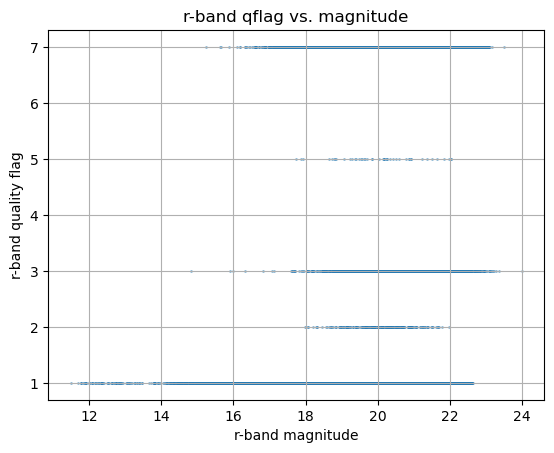

In [22]:
plt.scatter(contents['mis_r'], contents['qflag_r'], s=1, alpha=0.5)
plt.xlabel('r-band magnitude')
plt.ylabel('r-band quality flag')
plt.title('r-band qflag vs. magnitude')
plt.grid(True)

In [8]:
# === Load in PanSTARRS Isochrone File ===
isochrone_file = "/home/bernthold.17/SURP2025/Transforms/MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.4_PanSTARRS.iso.cmd"
print(f"Reading isochrone file from: {isochrone_file}")

logage = 10
isochrone = load_iso(isochrone_file, logage)

isochrone_file_columns = ['Radius_Estimate', 'log10_isochrone_age_yr', 'initial_mass', 'star_mass', 'log_Teff', 'log_g', 'log_L', '[Fe/H]_init',
                          '[Fe/H]', 'PS_g', 'PS_r', 'PS_i', 'PS_z', 'PS_y', 'PS_w', 'PS_open', 'phase']
isochrone.columns = isochrone_file_columns

Reading isochrone file from: /home/bernthold.17/SURP2025/Transforms/MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.4_PanSTARRS.iso.cmd


/tmp/slurmtmp.9109775/ipykernel_2222890/1633689941.py:33: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0         1.449754
1         1.470619
2         1.510297
3         1.550594
4         1.591545
            ...   
105589    0.015550
105590    0.015499
105591    0.015449
105592    0.015401
105593    0.015353
Length: 105594, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))


## Convert from Absolute to Apparent Magnitude

In [9]:
d = 8000 # distance to the Bulge in parsecs, this will be needed for converting to apparent magnitude

ps1_iso_g = isochrone.loc[:,'PS_g'] + 5*np.log10(d) - 5
ps1_iso_r = isochrone.loc[:,'PS_r'] + 5*np.log10(d) - 5
ps1_iso_i = isochrone.loc[:,'PS_i'] + 5*np.log10(d) - 5
ps1_iso_z = isochrone.loc[:,'PS_z'] + 5*np.log10(d) - 5

#print(ps1_iso_g, ps1_iso_r, ps1_iso_i, ps1_iso_z)

## Using Extinction and Reddening Values from rcfit code to Estimate Stellar Radii

In [10]:
R_v = 3.1 # Ratio of total to selective extinction for the Milky Way, Rv = Av / E(B-V)
# fliter_lambda = [0.473, 0.642, 0.784, 0.926] # g, r, i, z, in microns from DECam

r_rc = 15.855734905524415
r = filtered_contents.loc[:, 'mis_r']

A_r = 0.7798146039198492

E_rmz = 0.34461858518480504

R_r = 2.2628338616783137

In [11]:
z_rc = 15.079085656946738
z = filtered_contents.loc[:, 'mis_z']

A_z = 0.41610270566272867

E_rmz_z = 0.34838788091343875

R_z = 1.1943661891215858

In [12]:
g_rc = 16.967472753476354
g = filtered_contents.loc[:, 'mis_g']

A_g = 1.1299591030708296

E_gmi = 0.45925969046657245

R_g = 2.4603925110929685

In [13]:
i_rc = 15.410868457783632
i = filtered_contents.loc[:, 'mis_i']

A_i = 0.5674468654068576

E_gmi_i = 0.4932267870613054
gmi = g - i

R_i = 1.1504786039455863

In [14]:
r_dred = r - A_r

z_dred = z - A_z

g_dred = g - A_g

i_dred = i - A_i

gmi_dred = gmi - E_gmi_i

# print(f'Dereddening in the r-Band = {r_dred}, ' f'Dereddening in the z-Band= {z_dred},' 
#      f'Dereddening in the g-Band= {g_dred}, ' f'Dereddening in the i-Band= {i_dred},'
#      f'Dereddening of gmi = {gmi_dred}')

## Radius Estimates

In [15]:
# Based on magnitudes in isochrones (converted from absolute to apparent)
diameters, radius = gmi_diam_zang(gmi_dred, i_dred, 8.0) # dereddened gmi, dereddend i, distance of Galactic Bulge in kpc

### PanSTARRS Isochone

In [16]:
ps1_iso_diameters, ps1_iso_radius = gmi_diam_zang(ps1_iso_g - ps1_iso_i, ps1_iso_i, 8.0)

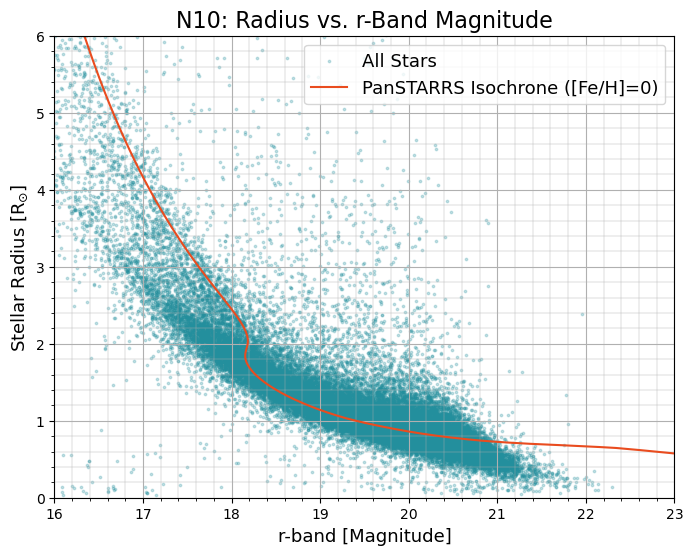

In [17]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(r_dred, radius, s=3, c='#238F9D', label='All Stars', alpha=0.25)
plt.plot(ps1_iso_r, ps1_iso_radius, '#E94C1F', ms = 3, label = 'PanSTARRS Isochrone ([Fe/H]=0)', alpha = 1)

plt.xlim(16.0, 23.0)
plt.ylim(0.0, 6.0)

plt.title("N10: Radius vs. r-Band Magnitude", fontsize = 16)
plt.xlabel('r-band [Magnitude]', fontsize = 13)
plt.ylabel('Stellar Radius [R$_{\odot}$]', fontsize = 13)

ax = plt.gca()
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

plt.grid(which='major')
plt.grid(which='minor', lw=0.3)

plt.legend(loc = 'best', fontsize = 13)
plt.show()

In [18]:
print(radius)

366      0.614965
375      3.566657
381      2.734282
408      5.279775
410      6.461321
           ...   
78266    1.589649
78267    0.592979
78268    1.371067
78272    2.834182
78277    1.289490
Length: 50820, dtype: float64


In [19]:
def myavg(radius):
    """
    This function computes the mean (average) of a list of values.
    
    Parameters
    ----------
    radius: list of integers or floats
        The list of numbers used for computing the mean.
        
    Returns
    -------
    mean: float
        The sum of all values in the list divided by the number of values.
        
    Usage
    -----
    >>> mean = myavg(radius)
    >>> print(mean)
    """
    return sum(radius) / len(radius)

In [20]:
def mystd(radius):
    """
    This function computes the standard deviation of a list of values.
    
    Parameters
    ----------
    radius: list of integers or floats
        The list of numbers used for computing the standard deviation.
        
    Returns
    -------
    standard_deviation: float
        The standard deviation of the list of values.
        
    Usage
    -----
    >>> standard_deviation = mystd(radius)
    >>> print(standard_deviation)
    """
    squares = [ x**2 for x in radius ]
    variance = myavg(squares) - (myavg(radius))**2
    stdev = variance**0.5
    return stdev

In [23]:
mean = myavg(radius)
print(mean)

standard_deviation = mystd(radius)
print(standard_deviation)

1.5894662860341728
2.294394402934451


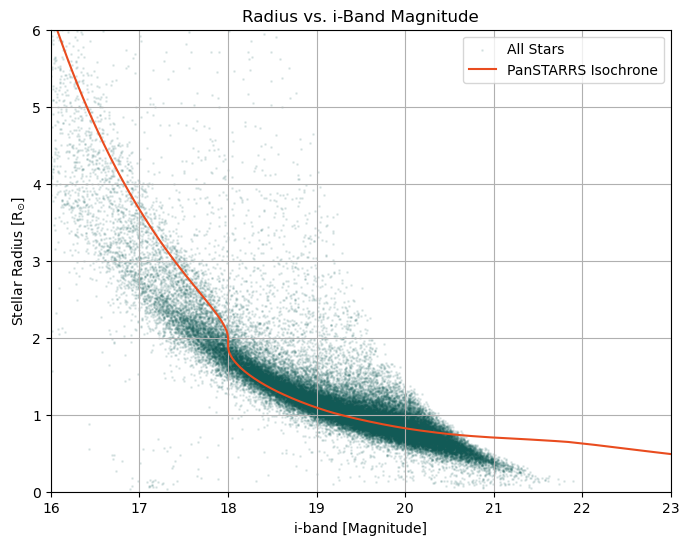

In [18]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(i_dred, radius, s=1, c = '#125A56', label='All Stars', alpha=0.1)
#plt.plot(ps1_iso_i, isochrone.loc[:,'Radius_Estimate'], '#E94C1F')
plt.plot(ps1_iso_i, ps1_iso_radius, '#E94C1F', label = 'PanSTARRS Isochrone', alpha = 1)

plt.xlim(16.0, 23.0)
plt.ylim(0.0, 6.0)

plt.title("Radius vs. i-Band Magnitude")
plt.xlabel('i-band [Magnitude]')
plt.ylabel('Stellar Radius [R$_{\odot}$]')

plt.legend(loc = 'best')
plt.grid(True)
plt.show()

### DECam Isochrone

In [24]:
# === Load in DECam Isochrone File ===
decam_isochrone_file = "/home/bernthold.17/SURP2025/Transforms/MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.4_DECam.iso.cmd"
print(f"Reading isochrone file from: {isochrone_file}")

logage = 10
decam_isochrone = load_iso(decam_isochrone_file, logage)

decam_isochrone_file_columns = ['Radius_Estimate', 'log10_isochrone_age_yr', 'initial_mass', 'star_mass', 'log_Teff', 'log_g', 'log_L', '[Fe/H]_init',
            '[Fe/H]', 'DECam_u', 'DECam_g', 'DECam_r', 'DECam_i', 'DECam_z', 'DECam_Y', 'phase']
decam_isochrone.columns = decam_isochrone_file_columns

Reading isochrone file from: /home/bernthold.17/SURP2025/Transforms/MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.4_PanSTARRS.iso.cmd


/tmp/slurmtmp.8859565/ipykernel_2508405/1633689941.py:33: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0         1.449754
1         1.470619
2         1.510297
3         1.550594
4         1.591545
            ...   
105589    0.015550
105590    0.015499
105591    0.015449
105592    0.015401
105593    0.015353
Length: 105594, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))


In [25]:
decam_iso_g = decam_isochrone.loc[:,'DECam_g'] + 5*np.log10(d) - 5
decam_iso_r = decam_isochrone.loc[:,'DECam_r'] + 5*np.log10(d) - 5
decam_iso_i = decam_isochrone.loc[:,'DECam_i'] + 5*np.log10(d) - 5
decam_iso_z = decam_isochrone.loc[:,'DECam_z'] + 5*np.log10(d) - 5

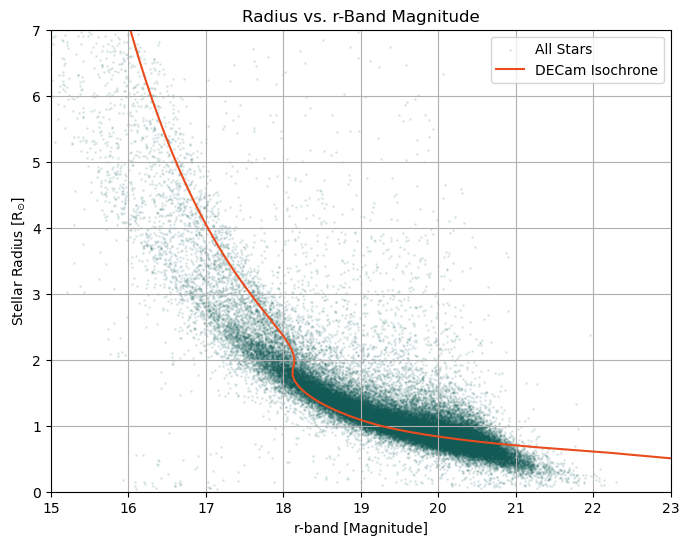

In [26]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(r_dred, radius, s=1, c='#125A56', label='All Stars', alpha=0.1)
plt.plot(decam_iso_r, decam_isochrone.loc[:,'Radius_Estimate'], '#E94C1F', label = 'DECam Isochrone')
#plt.plot(ps1_iso_r, ps1_iso_radius, 'r-', label = 'PanSTARRS Isochrone')

plt.xlim(15.0, 23.0)
plt.ylim(0.0, 7.0)

plt.title('Radius vs. r-Band Magnitude')
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Stellar Radius [R$_{\odot}$]')

plt.grid(True)
plt.legend(loc = 'best')

plt.show()

### Residuals

In [19]:
# PanSTARRS
# Create interpolation function (no extrapolation)
ps1_radius_interpolation = interp1d(ps1_iso_r, ps1_iso_radius)

# Get interpolation range
r_min, r_max = ps1_iso_r.min(), ps1_iso_r.max()

# Create a mask for valid r_dred values
valid_mask = (r_dred >= r_min) & (r_dred <= r_max)

# Initialize residuals with NaNs
ps1_radius_residual = np.full_like(radius, np.nan)

# Compute residuals only where interpolation is valid
ps1_radius_residual[valid_mask] = (
    (radius[valid_mask] - ps1_radius_interpolation(r_dred[valid_mask])) / radius[valid_mask]
)

# Compute binned statistics on valid residuals
ps1_residual_vals, ps1_residual_edges, ps1_residual_bins = binned_statistic(
    r_dred[valid_mask],
    ps1_radius_residual[valid_mask],
    statistic=np.nanmedian,
    bins=25,
    range=[14.0, 23.0]
)

In [1]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(r_dred, ps1_radius_residual, c = '#238F9D', s = 3, label = 'All Stars', alpha = 0.25)
plt.plot(0.5 * (ps1_residual_edges[:-1] + ps1_residual_edges[1:]), ps1_residual_vals, '#A01813', 
         label = 'PanSTARRS Residual')
plt.axhline(y = 1, color = '#FD9A44', linestyle = '--', label = '$+1 \sigma$')
plt.axhline(y = -1, color = '#FD9A44', linestyle = '--', label = '$-1 \sigma$')
plt.title('N10: PanSTARRS Residual of Radii in the r_Band', fontsize = 16)
plt.xlabel('r-Band [Magnitude]', fontsize = 13)
plt.ylabel('Fractional Residual [$R_{\odot}$]', fontsize = 13)

plt.xlim(13, 23)
plt.ylim(-3, 3)

ax = plt.gca()
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

plt.grid(which='major')
plt.grid(which='minor', lw=0.3)

plt.legend(loc = 'best')
plt.show()

NameError: name 'plt' is not defined

In [32]:
# DECam
# Create interpolation function (no extrapolation)
decam_radius_interpolation = interp1d(decam_iso_r, decam_isochrone.loc[:,'Radius_Estimate'])

# Get interpolation range
r_min, r_max = decam_iso_r.min(), decam_iso_r.max()

# Create a mask for valid r_dred values
valid_mask = (r_dred >= r_min) & (r_dred <= r_max)

# Initialize residuals with NaNs
decam_radius_residual = np.full_like(radius, np.nan)

# Compute residuals only where interpolation is valid
decam_radius_residual[valid_mask] = (
    (radius[valid_mask] - decam_radius_interpolation(r_dred[valid_mask])) / radius[valid_mask]
)

# Compute binned statistics on valid residuals
decam_residual_vals, decam_residual_edges, decam_residual_bins = binned_statistic(
    r_dred[valid_mask],
    decam_radius_residual[valid_mask],
    statistic=np.nanmedian,
    bins=25,
    range=[14.0, 23.0]
)

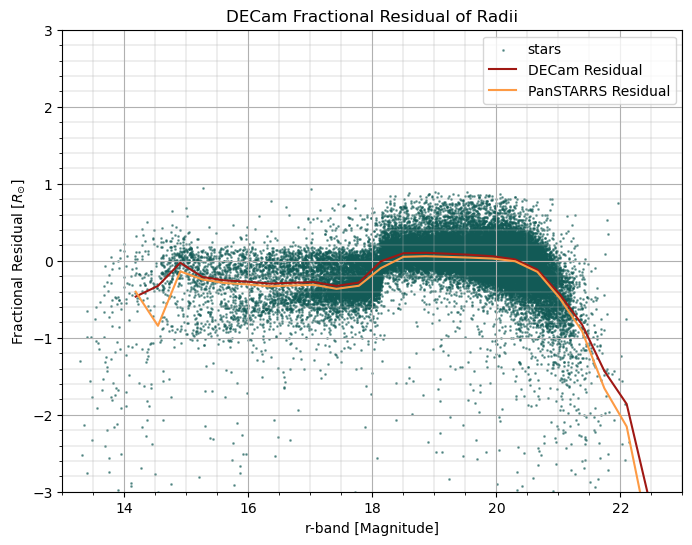

In [33]:
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(r_dred, decam_radius_residual, c ='#125A56', s = 1, label = 'stars', alpha = 0.5)
plt.plot(0.5 * (decam_residual_edges[:-1] + decam_residual_edges[1:]), decam_residual_vals, '#A01813', label = 'DECam Residual')
plt.plot(0.5 * (ps1_residual_edges[:-1] + ps1_residual_edges[1:]), ps1_residual_vals, '#FD9A44', label = 'PanSTARRS Residual')
plt.title('DECam Fractional Residual of Radii')
plt.xlabel('r-band [Magnitude]')
plt.ylabel('Fractional Residual [$R_{\odot}$]')

plt.xlim(13, 23)
plt.ylim(-3, 3)

ax = plt.gca()
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

plt.grid(which='major')
plt.grid(which='minor', lw=0.3)

plt.legend(loc = 'best')
plt.show()